In [34]:
import pandas as pd
import yaml

with open("../config.yaml") as f:
    config = yaml.safe_load(f)

print(config["data"]["red_url"])

https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv


In [35]:
red = pd.read_csv(config["data"]["red_url"], sep=";")
red["wine_type"] = "red"
print(red.shape)
red.head(20)
white = pd.read_csv(config["data"]["white_url"], sep=";")
white["wine_type"] = "white"
print(white.shape)
white.head(20)
df = pd.concat([red, white], ignore_index=True)
print(df.shape)
pd.concat([df[df["wine_type"]=="red"].head(15), df[df["wine_type"]=="white"].head(15)])

(1599, 13)
(4898, 13)
(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.880,0.00,2.60,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.760,0.04,2.30,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.280,0.56,1.90,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
5,7.4,0.660,0.00,1.80,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,red
6,7.9,0.600,0.06,1.60,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5,red
7,7.3,0.650,0.00,1.20,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7,red
8,7.8,0.580,0.02,2.00,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7,red
9,7.5,0.500,0.36,6.10,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5,red


In [36]:
print(df.shape)
print(df.dtypes)
print("Missing values:", df.isna().sum().sum())
print("Duplicates:", df.duplicated().sum())

(6497, 13)
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                   str
dtype: object
Missing values: 0
Duplicates: 1177


In [37]:
df["quality"].value_counts().sort_index()

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

Note: you may need to restart the kernel to use updated packages.
quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


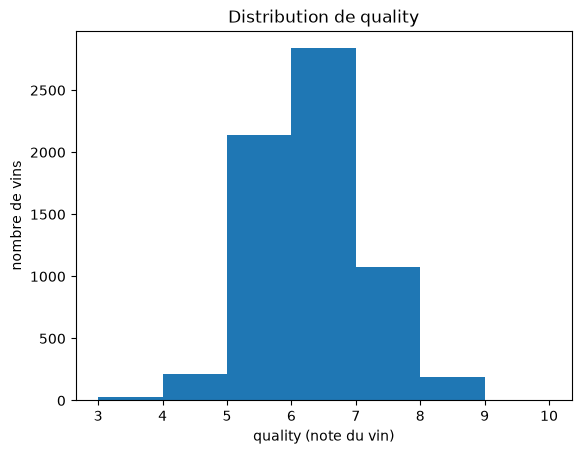

In [38]:
%pip install matplotlib seaborn
import matplotlib.pyplot as plt

print(df["quality"].value_counts().sort_index())

plt.hist(df["quality"], bins=range(3, 11))
plt.title("Distribution de quality")
plt.xlabel("quality (note du vin)")
plt.ylabel("nombre de vins")
plt.show()



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


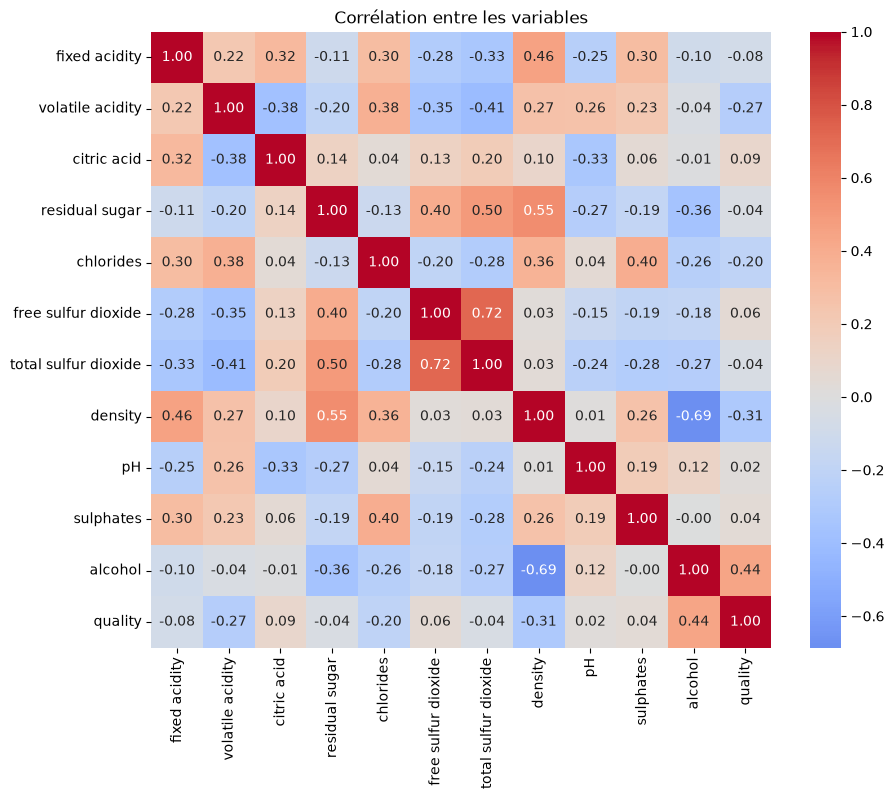

In [39]:
%pip install seaborn
import seaborn as sns

corr = df.drop(columns="wine_type").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélation entre les variables")
plt.show()

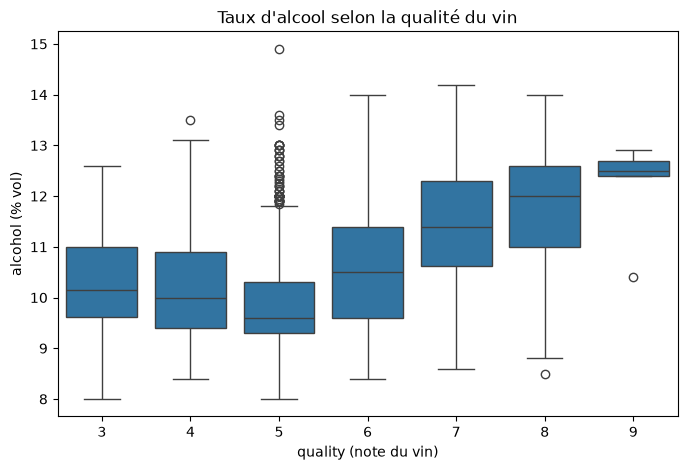

In [40]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="quality", y="alcohol")
plt.title("Taux d'alcool selon la qualité du vin")
plt.xlabel("quality (note du vin)")
plt.ylabel("alcohol (% vol)")
plt.show()

In [41]:
cutoff = config["model"]["good_quality_cutoff"]
df["good"] = (df["quality"] >= cutoff).astype(int)

print(df["good"].value_counts())
print(df["good"].value_counts(normalize=True).round(3))

good
1    4113
0    2384
Name: count, dtype: int64
good
1    0.633
0    0.367
Name: proportion, dtype: float64
